# Lab 12 — Probabilistic Ranking: Language Models, Topics and PageRank

**Information Retrieval course · final lab**

Two ways to decide which document should come first:

| | Part 1 — Language models | Part 2 — PageRank |
|---|---|---|
| Question | How likely is this document to **generate the query**? | How **important** is this document, whatever the query? |
| Depends on the query? | yes, $P(q \mid d)$ | no, a prior $P(d)$ |
| Built from | word counts in the text | links between documents |

They fit together in one formula:

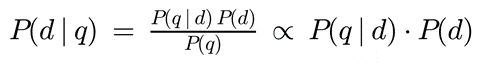
### Contents
0. Setup · 1. Language models · 2. Topic modelling · 3. PageRank · 4. Wrap-up

In [3]:
!uv tree -d 1

Resolved 240 packages in 3ms
ir v0.1.0
├── altair v6.2.2
├── annoy v1.17.3
├── beautifulsoup4 v4.15.0
├── bs4 v0.0.2
├── feedparser v6.0.14
├── ipykernel v7.3.0
├── librosa v0.11.0
├── matplotlib v3.10.9
├── nltk v3.10.3
├── nmslib v2.1.2
├── pandas v2.3.3
├── pygtrie v2.5.0
├── requests v2.34.2
├── scikit-learn v1.7.2
├── selenium v4.48.0
├── sentence-transformers v6.2.0
└── statsmodels v0.15.0


## 0. Setup

We use only `numpy`, `scipy`, `matplotlib` and `scikit-learn`. Stop words come from scikit-learn's built-in English list, so no extra downloads are needed.

The data is the topic-modelling collection we used before ([GitHub](https://github.com/IUCVLab/information-retrieval/blob/main/datasets/topic-modelling.zip)): 15,002 documents from four sources, already lower-cased and without punctuation. Put the four `.txt` files in `../datasets/topic-modelling/` (or next to this notebook).

In [4]:
import os
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

plt.rcParams["figure.dpi"] = 100

In [ ]:
FILES = [("fuel", "testdata_news_fuel_845docs.txt"),
         ("brain_injury", "testdata_braininjury_10000docs.txt"),
         ("economy", "testdata_news_economy_2073docs.txt"),
         ("music", "testdata_news_music_2084docs.txt")]

folder = next((f for f in ["../datasets/topic-modelling", "./datasets/topic-modelling", "."]
               if os.path.exists(os.path.join(f, FILES[0][1]))), None)
assert folder, "Dataset files not found: put them in ../datasets/topic-modelling/"

all_data, labels = [], []
for category, fname in FILES:
    with open(os.path.join(folder, fname), encoding="utf-8") as fp:
        docs = [line.strip() for line in fp]
    all_data += docs
    labels += [category] * len(docs)
labels = np.array(labels)

print("# of documents:", len(all_data))
assert len(all_data) == 15002
print(Counter(labels))
print(all_data[0][:300] + "...")

# of documents: 15002
Counter({np.str_('brain_injury'): 10000, np.str_('music'): 2084, np.str_('economy'): 2073, np.str_('fuel'): 845})
the new york times said editorial for tuesday jan new year day has way stealing down upon coming the shadow the christmas week and its own scintillating eve you celebrated midnight last night was easy little illusory think the festivities gesture dismissal warding off the old year and its associated...


---
# Part 1 — Ranking with language models

**Idea.** A good piece of search advice is: *type the words you expect to see in the document you want.* The language-model approach turns this into a ranking rule: each document is a little machine that produces words at random, and we rank documents by how likely their machine is to produce the query.

**Definitions**
- **Language model** of a document $M_d$: a probability for every word, $P(t \mid M_d)$.
- **Unigram model**: words are produced independently of each other, so
  $$P(q \mid d) = \prod_{t \in q} P(t \mid M_d)^{\,tf_{t,q}}$$
- **Maximum-likelihood estimate (MLE)**: count and divide,
  $$P_{mle}(t \mid M_d) = \frac{tf_{t,d}}{L_d}$$
  where $tf_{t,d}$ is how often $t$ occurs in $d$ and $L_d$ is the length of $d$ in tokens.

**Why $P(q \mid d)$?** We want $P(d \mid q)$. By Bayes' rule $P(d \mid q) = \frac{P(q \mid d)\,P(d)}{P(q)}$. $P(q)$ is the same for every document, and if we assume all documents are equally likely a priori, $P(d)$ drops out too. Keep that last assumption in mind: Part 3 replaces it.

## 1.1 Document–term matrix

In [6]:
vectorizer = CountVectorizer(stop_words="english", min_df=2)   # drop words seen in only one doc
counts_data = vectorizer.fit_transform(all_data)               # sparse, docs × terms
terms = vectorizer.get_feature_names_out()

print("matrix shape", counts_data.shape)
print("vocabulary size", len(terms))
print(f"non-zero cells: {counts_data.nnz / np.prod(counts_data.shape):.3%}")

matrix shape (15002, 60382)
vocabulary size 60382
non-zero cells: 0.310%


Less than 1% of the cells are non-zero. Hold on to that number: it causes the main problem in section 1.3.

## 1.2 What the word counts look like

The black line shows the 60 most frequent words of the whole collection, each count divided by the count of the top word. The dots show the same words inside each of the four sub-collections.

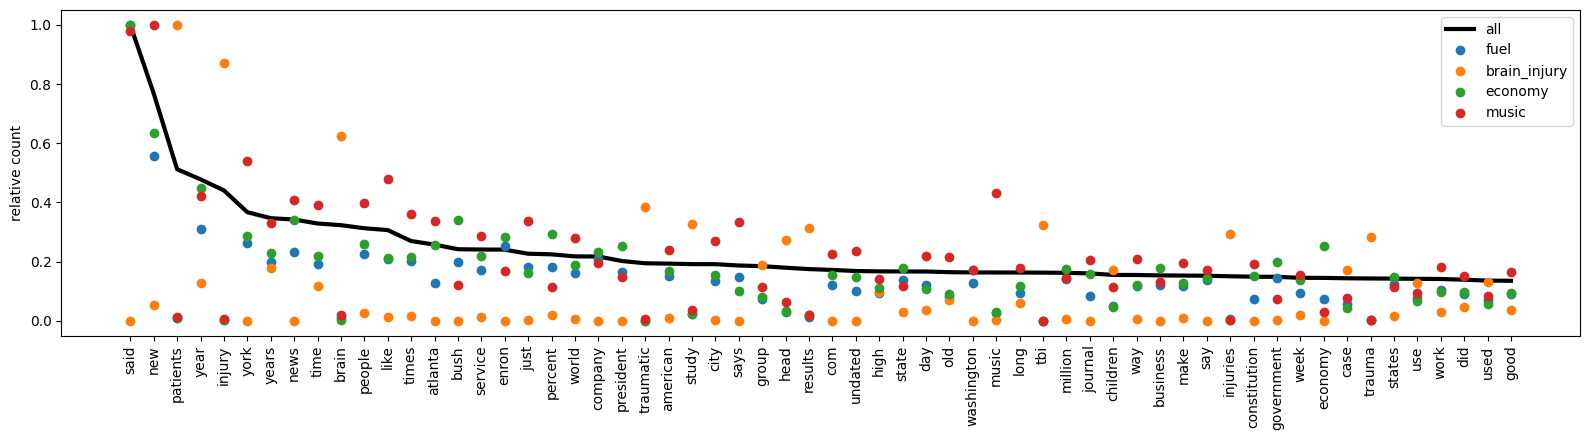

In [7]:
counts_total = counts_data.sum(axis=0).A1
top = np.argsort(counts_total)[::-1][:60]

plt.figure(figsize=(16, 4.5))
plt.plot(counts_total[top] / counts_total[top[0]], lw=3, c="black", label="all")
for category, _ in FILES:
    c = counts_data[labels == category].sum(axis=0).A1
    plt.plot(c[top] / c.max(), ls="", marker="o", ms=6, label=category)
plt.xticks(range(len(top)), terms[top], rotation=90)
plt.ylabel("relative count"); plt.legend(); plt.tight_layout(); plt.show()

**Discuss**
1. Why does the black curve drop so fast?
2. What does a dot far above the line mean? Far below?
3. Why do the four sub-collections have different top words?
4. Where are the words that appear almost everywhere?

<details><summary><b>Notes</b></summary>

1. **Zipf's law**: a word's frequency is roughly proportional to 1 / its rank. A few words are very frequent, and there is a long tail of rare ones.
2. A dot above the line marks a word that is more typical of that sub-collection than of the whole collection (e.g. *patients* for brain_injury). That is exactly what makes it useful for ranking and for topic modelling. A dot below marks a word that is rare there.
3. Each source has its own vocabulary. The 10,000 medical abstracts dominate the collection totals, so the black line looks mostly like brain_injury.
4. Classic stop words (*the, of, and*) are already removed. What is left at the top are collection-specific "stop words" such as *said, new, year*. They appear in nearly every news text and don't tell documents apart.
</details>

## 1.3 Smoothing

**The problem.** With MLE, one query word missing from a document gives $P(t \mid M_d) = 0$, and the whole product becomes 0. Most documents miss at least one word of most queries, so most scores are 0 and can't be ranked.

**The fix: smoothing**, which gives unseen words a small probability.
- **Additive (Laplace / Lidstone)**: add $\alpha$ to every count,
  $$P(t \mid d) = \frac{tf_{t,d} + \alpha}{L_d + \alpha\,|V|}$$
- **Jelinek–Mercer**: mix the document model with the **collection model** $M_c$ (all documents together),
  $$P(t \mid d) = \lambda\,\frac{tf_{t,d}}{L_d} + (1-\lambda)\,\frac{cf_t}{L_c}$$
  where $cf_t$ is the count of $t$ in the whole collection and $L_c$ is the total number of tokens. $\lambda$ is the weight of the document. See [IIR, Chapter 12](https://nlp.stanford.edu/IR-book/html/htmledition/language-models-for-information-retrieval-1.html).

**Implementation note.** Multiplying many small probabilities underflows to 0.0 in floating point, so we add **logarithms** instead: $\log P(q \mid d) = \sum_t tf_{t,q}\,\log P(t \mid d)$. The ranking is the same. We also compute all documents at once with matrix operations instead of looping over them.

In [8]:
analyzer = vectorizer.build_analyzer()        # the same tokenizer + stop words as the index
term_index = vectorizer.vocabulary_           # term -> column
doc_lengths = np.maximum(counts_data.sum(axis=1).A1, 1)  # L_d (3 docs are empty: avoid 0/0)
coll_prob = counts_total / counts_total.sum() # cf_t / L_c


def prepare_query(raw_query):
    return Counter(t for t in analyzer(raw_query) if t in term_index)


def lm_rank_documents(query, tdm=counts_data, smoothing="jelinek", param=0.5):
    # query: Counter term -> count. Returns (log-scores, doc ids sorted best first).
    # param = alpha (additive) or lambda, the document weight (jelinek)
    ids = [term_index[t] for t in query]
    q_tf = np.array([query[t] for t in query], dtype=float)
    tf = tdm[:, ids].toarray()                # docs × query terms, tiny and dense
    L = doc_lengths[:, None]

    if smoothing == "additive":
        p = (tf + param) / (L + param * tdm.shape[1])
    elif smoothing == "jelinek":
        p = param * tf / L + (1 - param) * coll_prob[ids]
    else:                                     # no smoothing (MLE)
        p = tf / L

    with np.errstate(divide="ignore"):
        scores = np.log(p) @ q_tf             # log P(q|d); -inf when some p = 0
    return scores, np.argsort(-scores, kind="stable")

## 1.4 Testing

For each query we print the top 5 documents and **precision@10**: the share of the top 10 results that come from the expected sub-collection.

In [9]:
user_queries = {"piano concert": "music",
                "symptoms of head trauma": "brain_injury",
                "wall street journal": "economy",
                "oil prices and gasoline": "fuel"}


def process_query(raw_query, expected, smoothing, param, show=5):
    query = prepare_query(raw_query)
    scores, order = lm_rank_documents(query, smoothing=smoothing, param=param)
    p10 = np.mean(labels[order[:10]] == expected)
    n_zero = np.isneginf(scores).sum()
    print(f"\033[95m{raw_query}\033[0m  {dict(query)}  P@10={p10:.1f}  zero-score docs={n_zero}")
    for d in order[:show]:
        print(f"   \033[1m{labels[d]:12s}\033[0m #{d:<5d} logP={scores[d]:8.2f} | {all_data[d][:80]}...")
    return p10


for smoothing, param in [("none", None), ("additive", 0.01), ("jelinek", 0.5)]:
    print(f"\n===== {smoothing} =====")
    p = [process_query(q, cat, smoothing, param, show=3) for q, cat in user_queries.items()]
    print(f"mean P@10 = {np.mean(p):.2f}")


===== none =====
piano concert  {'piano': 1, 'concert': 1}  P@10=1.0  zero-score docs=14965
   music        #13834 logP=   -8.93 | sometimes the most satisfying renovation the one that doesn happen two years ago...
   music        #13808 logP=   -9.33 | playing carnegie hall concert performer dream when word leaked out that america ...
   music        #13588 logP=   -9.38 | igor kipnis the virtuoso harpsichordist whose busy concert recording career made...
symptoms of head trauma  {'symptoms': 1, 'head': 1, 'trauma': 1}  P@10=1.0  zero-score docs=14930
   brain_injury #10200 logP=   -8.73 | incidental finding chiari malformation with progression symptoms after head trau...
   brain_injury #2335  logP=   -9.05 | conversion symptomatic chiari malformation after minor head neck trauma objectiv...
   brain_injury #2843  logP=   -9.61 | characteristics that distinguish abusive from nonabusive head trauma among young...
wall street journal  {'wall': 1, 'street': 1, 'journal': 1}  P@10=0.5  

Is there a best parameter? Sweep it and compare mean P@10 over the queries.

In [10]:
def mean_p10(smoothing, param):
    return np.mean([np.mean(labels[lm_rank_documents(prepare_query(q), smoothing=smoothing, param=param)[1][:10]] == cat) for q, cat in user_queries.items()])

for smoothing, params in [("additive", [0.001, 0.01, 0.1, 1]), ("jelinek", [0.1, 0.3, 0.5, 0.7, 0.9])]:
    print(smoothing.ljust(9), "  ".join(f"{p}: {mean_p10(smoothing, p):.2f}" for p in params))

additive  0.001: 0.75  0.01: 0.72  0.1: 0.88  1: 0.88
jelinek   0.1: 0.65  0.3: 0.70  0.5: 0.72  0.7: 0.75  0.9: 0.72


---
# Part 2 — Topic modelling with LDA

We know our collection has four sources. Can an algorithm find them from the words alone, without the labels?

**Definitions**
- **Topic**: a probability distribution over words. A "music" topic gives high probability to *music, album, band*.
- **LDA (Latent Dirichlet Allocation)**: assumes each document is a **mixture of topics**, and each word is produced by first picking a topic and then picking a word from it. Learning means finding the topics and the mixture for each document that best explain the counts.
- *Latent* means hidden: we never see the topics, only the words.

The probability of a word in a document is then:
 
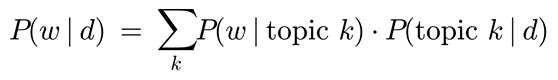


LDA doesn't need all 100k+ words. We keep the 5,000 most frequent words that appear in at least 10 documents and in at most half of them. This cuts the matrix down without re-tokenizing.

In [11]:
df = (counts_data > 0).sum(axis=0).A1
ok = np.where((df >= 10) & (df <= 0.5 * counts_data.shape[0]))[0]
keep = ok[np.argsort(-counts_total[ok])[:5000]]
X_lda, lda_terms = counts_data[:, keep], terms[keep]
print("LDA input:", X_lda.shape)

lda = LatentDirichletAllocation(n_components=4, learning_method="online",
                                max_iter=10, random_state=0, n_jobs=-1)
doc_topics = lda.fit_transform(X_lda)   # docs × topics, each row sums to 1


def print_topics(model, words, n_top_words=15):
    for k, topic in enumerate(model.components_):
        print(f"Topic #{k}: " + " ".join(words[topic.argsort()[::-1][:n_top_words]]))

print_topics(lda, lda_terms)

LDA input: (15002, 5000)
Topic #0: new york news atlanta said like times music says time service undated people just journal
Topic #1: said bush president government new state states house united war washington people officials year budget
Topic #2: patients injury brain traumatic study results tbi injuries trauma head treatment severe outcome patient clinical
Topic #3: said company percent year enron new million companies market business economy years stock financial time


Each document's main topic is the one with the largest weight. Do the topics match the real sources?

In [14]:
main_topic = doc_topics.argmax(axis=1)
cats = [c for c, _ in FILES]
table = np.array([[np.sum((labels == c) & (main_topic == k)) for k in range(lda.n_components)] for c in cats])

print("rows: true source, columns: main LDA topic")
print(f"{'':14s}" + "".join(f"T{k:<7d}" for k in range(lda.n_components)))
for c, row in zip(cats, table):
    print(f"{c:14s}" + "".join(f"{v:<8d}" for v in row))

rows: true source, columns: main LDA topic
              T0      T1      T2      T3      
fuel          299     239     2       305     
brain_injury  135     56      9768    41      
economy       562     719     2       790     
music         1834    85      1       164     


**Discuss**
1. Name each topic from its top words. Which source is found most cleanly? Which ones get mixed up?
2. Fuel didn't get its own topic, but one topic is made of words like *undated, cox, constitution*. Why?
3. Try `n_components=5` and `6`. Do new, meaningful topics appear?
4. How could topics help retrieval?

<details><summary><b>Notes</b></summary>

1. With `random_state=0` we get a medical topic (it captures almost all brain_injury abstracts), an economy/politics topic (*bush, percent, enron*), a culture topic (*music, life, people*), and a "wire service" topic (*news, york, atlanta, undated, constitution, cox*). Fuel has no topic of its own: most fuel articles go to economy, since both talk about prices, companies and percent.
2. LDA explains word counts, not sources. The wire-service topic is made of newspaper metadata (agency names, *undated*, *moved*) that appears in all three news sources. Explaining those very frequent words is worth a whole topic, more than separating 845 fuel articles from economy. This is a reason to clean boilerplate before topic modelling.
3. More topics usually split the big groups further. Choosing the number of topics is a judgement call, often guided by coherence measures and by reading the topics.
4. Topics give a low-dimensional representation of documents, like LSA. Uses: matching a query to documents that use different words for the same subject, faceted browsing, diversifying results, and smoothing a document model with its topics' words.
</details>

---
# Part 3 — PageRank

Language models look only at the text. On the web, the **links** between pages also carry information: a link is a vote for the page it points to, and votes from important pages count more.

**Random surfer model.** Someone clicks links at random. With probability $\alpha = 0.85$ they follow a random link on the current page; otherwise they get bored and jump to a random page. A page's **PageRank** is the share of time the surfer spends on it in the long run.

**Data.** 40 Wikipedia articles about IR and the links between them. $A_{ij} = 1$ if page $j$ links to page $i$, so column $j$ holds the outgoing links of page $j$. (The matrix was extracted with the `wikipedia` package and is embedded below, so no download is needed.)

40 pages, 184 links, pages with no outgoing links: 4


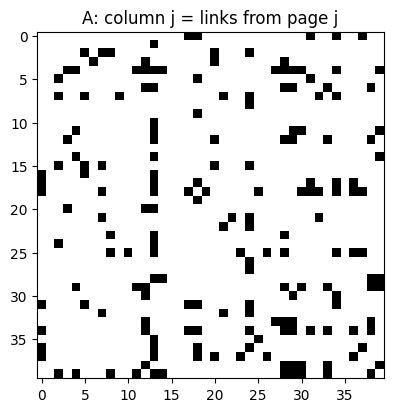

In [15]:
pages = ["Bag-of-words model", "Bayes' theorem", "Cluster analysis", "Content-based image retrieval", "Database", "Deep learning", "Desktop search", "Dimensionality reduction", "Discounted Cumulative Gain", "Eigenvector", "Full-text search", "Hypertext", "Image retrieval", "Information retrieval", "Information system", "K-nearest neighbors algorithm", "Language model", "Latent Dirichlet allocation", "Latent semantic analysis", "Low-rank approximation", "Multimedia information retrieval", "Netflix Prize", "Netflix", "Ranking (information retrieval)", "Recommender systems", "Relevance (information retrieval)", "Rocchio algorithm", "Search algorithm", "Search engines", "Semantic search", "Semantic web", "Sentiment analysis", "Similarity search", "Site search", "Text mining", "Text Retrieval Conference", "Tf–idf", "Vector space model", "Web crawler", "World Wide Web"]
Atext = "0000000000000000011000000000000100100100000000000000010000000000000000000000000000000101100000000000100010000000000000000000001000001000000010000000100000000000000110000001111000000000000111100010000100100000000000000010000000000001000000000000000000001100000000000000110001000010001001000100000000000100100000001010000000000000000000000000000010000000000000000000000000000000001000000000000000000000000000000000010000000000000000000000000000001000000001000000000000000110000000010001000000000100000010000000110001000010000000000000000000000000000000000000000000001000000001000000000000000000000000010010010100000000000010001000000000000000100001000000010000000000000000000000000010000000000001000010000000000001001010001000000100000100010100000100001110101100000000000000000000100000000000000000000000010000000011000000000000000000000000000000000100000000000000101000000010000000000000000000000000000100100000000000000000000000100001000000000000001000000000000010000000000100000000000000000000000000000000001010010000000001001010000010110000000000000000000000000010000000000000000000000000000000000000001000000000000000000000000000011000000000000000000000001100001000000110000000000000001010010000110000000000001000000000000000010000100000100001000000000001100000100000000010000000000001000000000000010010000000000000000000000000001000000000000001110000000010100000000000100001100000100011010100101000000000000001000000000001000000000000001000000000000100001000001000000000000100100000000000010000101001001000000000100000000000000010000000000000001110010000010010100010010110000000000000111001000010"

N = len(pages)
A = np.array([float(a) for a in Atext]).reshape(N, N)
print(f"{N} pages, {int(A.sum())} links, pages with no outgoing links: {int((A.sum(axis=0) == 0).sum())}")
plt.figure(figsize=(4.5, 4.5)); plt.imshow(A, cmap="Greys"); plt.title("A: column j = links from page j"); plt.show()

## 3.1 Stochastic matrix $M$

**Definition.** A (column-)**stochastic matrix** has non-negative entries and every column sums to 1. Column $j$ then gives the probabilities of moving from page $j$ to each other page.

Divide each column by its number of outgoing links. A **dangling page** has no outgoing links; the surfer would get stuck there, so we let them jump to any page with probability $1/N$. (Wikipedia calls this the [Markov matrix S](https://en.wikipedia.org/wiki/Google_matrix#Adjacency_matrix_A_and_Markov_matrix_S).)

In [16]:
out_degree = A.sum(axis=0)
M = np.where(out_degree > 0, A / np.maximum(out_degree, 1), 1.0 / N)
assert np.allclose(M.sum(axis=0), 1)

## 3.2 Google matrix $G$

Add the random jump ([construction](https://en.wikipedia.org/wiki/Google_matrix#Construction_of_Google_matrix_G)), with damping factor $\alpha = 0.85$:
$$G = \alpha M + \frac{1-\alpha}{N}\,\mathbb{1}\mathbb{1}^\top$$
Every entry of $G$ is positive, so the surfer can reach every page from every page, and the PageRank vector is unique.

In [17]:
def to_google(M, alpha=0.85):
    return alpha * M + (1 - alpha) / M.shape[0]

G = to_google(M)
assert np.allclose(G.sum(axis=0), 1)

## 3.3 Computing PageRank three ways

PageRank $R$ is the vector that doesn't change after one more step of the surfer: $R = G R$, with $\sum_i R_i = 1$. In other words, $R$ is the eigenvector of $G$ for eigenvalue 1.

**(a) Linear system.** Because $\sum_i R_i = 1$, $\frac{1-\alpha}{N}\mathbb{1}\mathbb{1}^\top R = \frac{1-\alpha}{N}\mathbb{1}$, so
$$R = \alpha M R + \frac{1-\alpha}{N}\mathbb{1} \quad\Longrightarrow\quad (I - \alpha M)\,R = \frac{1-\alpha}{N}\mathbb{1}$$

**(b) Power method.** Start anywhere and let the surfer walk: $R \leftarrow G R$ until it stops changing. Each step is one matrix–vector product. On the real web this is the only practical option.

**(c) Eigen-decomposition**, for checking only.

In [14]:
alpha = 0.85

# (a) linear system: solve instead of inverting the matrix
R_solve = np.linalg.solve(np.eye(N) - alpha * M, np.full(N, (1 - alpha) / N))

# (b) power method
R = np.full(N, 1.0 / N)
for it in range(1, 1001):
    R_next = G @ R
    if np.abs(R_next - R).sum() < 1e-12:
        break
    R = R_next
R_power = R_next
print(f"power method converged after {it} iterations")

# (c) eigenvector for the largest eigenvalue (= 1), scaled to sum to 1
evals, evecs = np.linalg.eig(G)
v = np.real(evecs[:, np.argmax(np.real(evals))])
R_eig = v / v.sum()

assert np.allclose(R_solve, R_power) and np.allclose(R_solve, R_eig)
print("all three methods agree; sum =", R_solve.sum().round(6))

power method converged after 83 iterations
all three methods agree; sum = 1.0


## 3.4 Ranking

rank  PageRank  in-links  page
   1    0.0795        12  Latent semantic analysis
   2    0.0658        12  Database
   3    0.0508        11  World Wide Web
   4    0.0488        11  Text mining
   5    0.0447         8  Semantic search
   6    0.0442         7  Dimensionality reduction
   7    0.0367         5  Bag-of-words model
   8    0.0343         9  Relevance (information retrieval)
   9    0.0334         6  Sentiment analysis
  10    0.0322         6  Latent Dirichlet allocation
  11    0.0321         4  Netflix Prize
  12    0.0303         5  Hypertext
  13    0.0300         7  Vector space model
  14    0.0290         4  Content-based image retrieval
  15    0.0281         7  Image retrieval


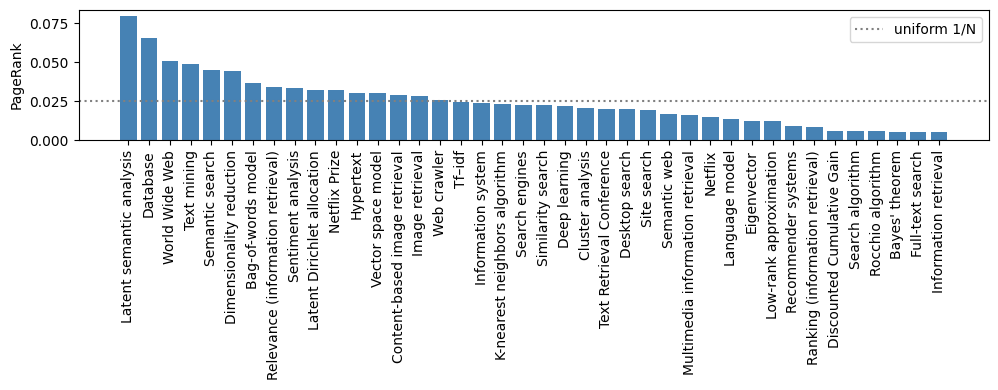

In [15]:
order = np.argsort(-R_power)
in_degree = A.sum(axis=1)
print(f"{'rank':>4}  {'PageRank':>8}  {'in-links':>8}  page")
for r, k in enumerate(order[:15], 1):
    print(f"{r:4d}  {R_power[k]:8.4f}  {int(in_degree[k]):8d}  {pages[k]}")

plt.figure(figsize=(10, 4))
plt.bar(range(N), R_power[order], color="steelblue")
plt.axhline(1 / N, color="grey", ls=":", label="uniform 1/N")
plt.xticks(range(N), [pages[k] for k in order], rotation=90)
plt.ylabel("PageRank"); plt.legend(); plt.tight_layout(); plt.show()

**Discuss**
1. Is PageRank the same as counting in-links? Find a page whose rank differs from its in-link count, and explain why.
2. Change $\alpha$ to 0.5 and 0.99. What happens to the ranking and to the number of power iterations?
3. Why do we need the $1/N$ fix for dangling pages and the random jump? What would go wrong without each?
4. How would a spammer try to raise a page's PageRank, and how could a search engine defend against it?

<details><summary><b>Notes</b></summary>

1. No. A link from a page that is itself important, and that has few outgoing links, is worth more than a link from an unimportant page with many links. Compare the PageRank and in-links columns.
2. Smaller $\alpha$ means more random jumps: the scores become closer to uniform and the method converges faster (the error shrinks roughly like $\alpha^k$). With $\alpha \to 1$ the link structure dominates and convergence is slow.
3. Without the dangling fix, columns of zeros make probability "leak out" and $M$ is not stochastic. Without the random jump, the surfer can get trapped in a group of pages that only link to each other, and the result may not be unique.
4. Link farms: many fake pages that all link to the target. Defences: TrustRank (start the random jumps only from trusted pages), detecting unusual link patterns, and `nofollow` links that don't pass on PageRank.
</details>


---
**This is the last lab of the course.** Over the semester we went from indexing words, through vector spaces, trees and graphs for nearest-neighbour search, to fingerprints for audio, and now probabilistic and link-based ranking. Every one of them answers the same two questions: *how do we represent documents and queries*, and *how do we find the best matches quickly*. Thank you, and good luck!